# 01 · Dữ liệu và đặc trưng

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
if not (ROOT / 'pyproject.toml').exists():
    ROOT = ROOT.parent
if not (ROOT / 'pyproject.toml').exists():
    raise FileNotFoundError('Mở notebook từ thư mục dự án hoặc notebooks/.')
sys.path.insert(0, str(ROOT))
from scripts import final_study as study
from IPython.display import display
study.style()

In [2]:
bars, samples, cfg, quality = study.prepare()
display(bars.groupby('symbol').agg(rows=('close','size'), first=('timestamp','min'), last=('timestamp','max')))
display(quality)
print('Đọc lại snapshot đã lưu và kiểm tra SHA256; không thu thập mới trong lượt này.')

Đọc lại snapshot đã lưu và kiểm tra SHA256; không thu thập mới trong lượt này.


,rows,first,last
symbol,,,
BTCUSDT,33910,2023-01-01 00:00:00+00:00,2026-11-13 23:00:00+00:00
ETHUSDT,33910,2023-01-01 00:00:00+00:00,2026-11-13 23:00:00+00:00


{'input_rows': 67820,
 'valid_rows': 67820,
 'quarantine_rows': 0,
 'duplicate_rows': 0,
 'gaps': [{'symbol': 'BTCUSDT',
   'after': '2023-03-24T11:00:00+00:00',
   'missing_bars': 2},
  {'symbol': 'ETHUSDT',
   'after': '2023-03-24T11:00:00+00:00',
   'missing_bars': 2}]}

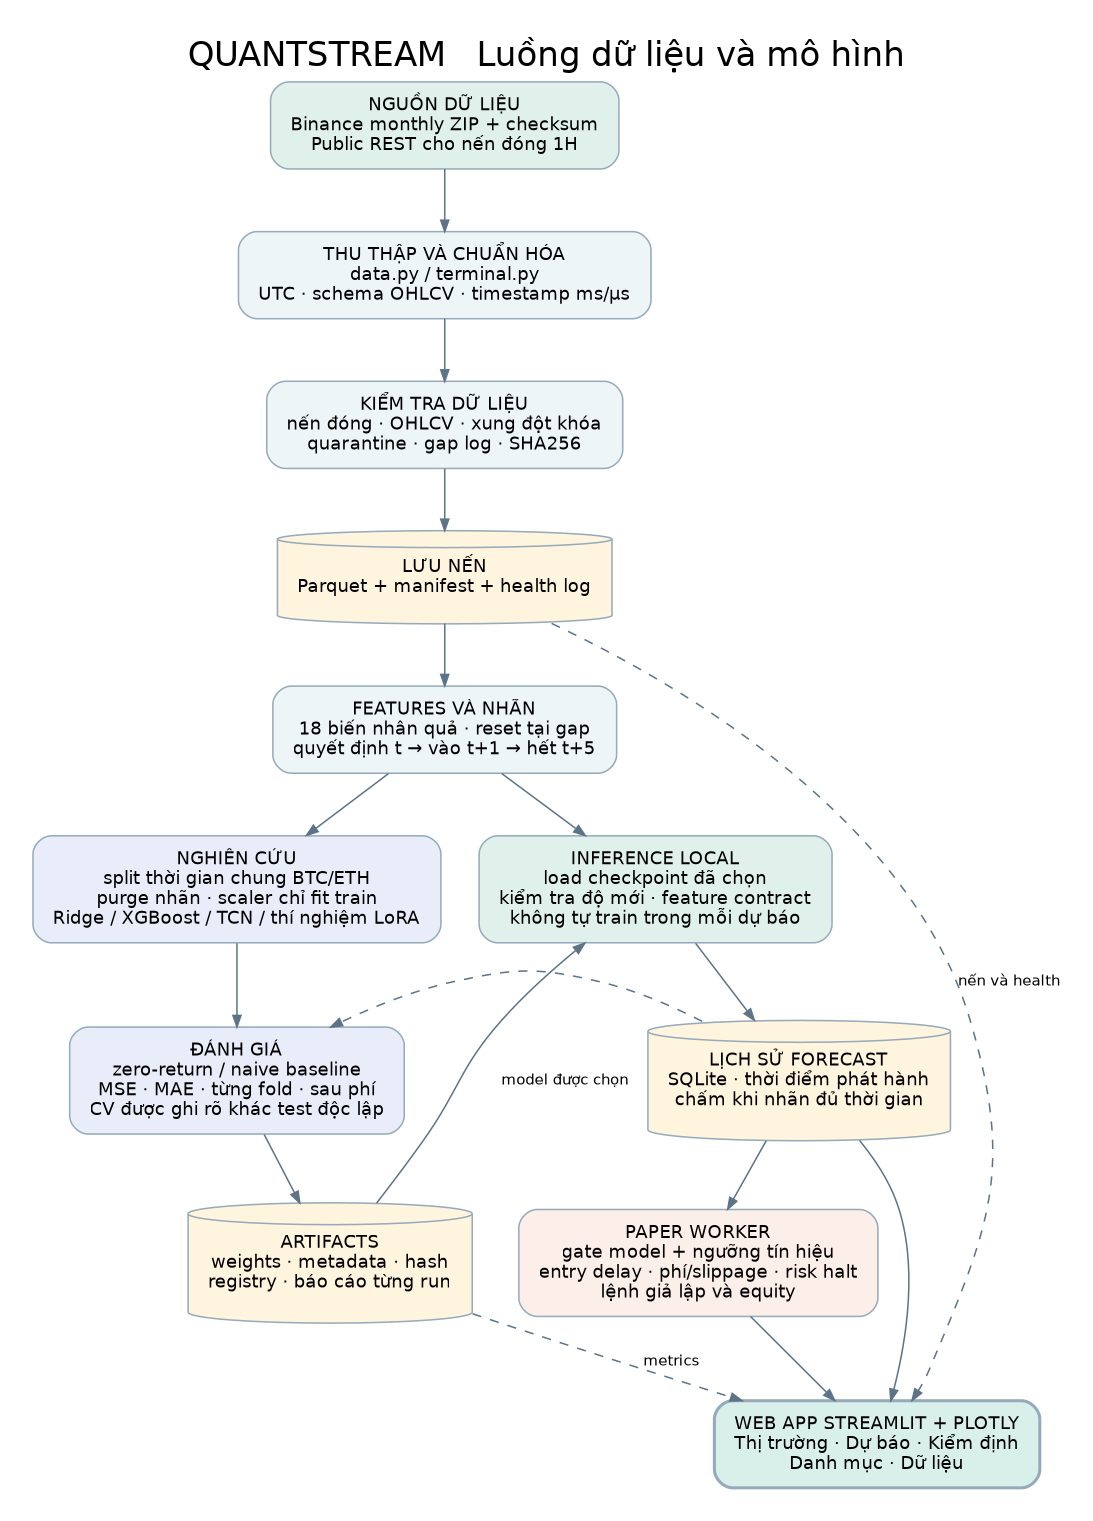

In [3]:
study.diagram('architecture')

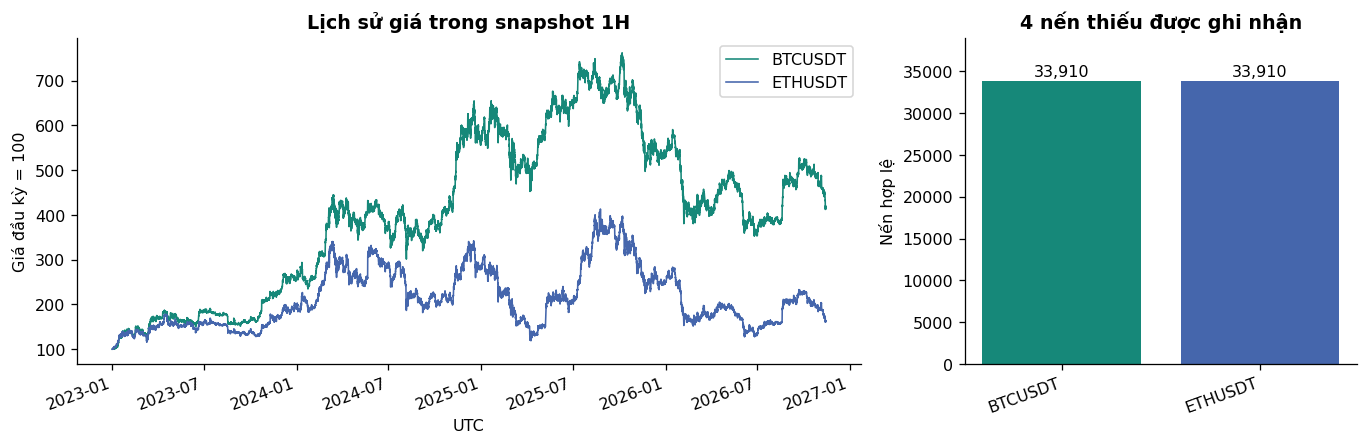

In [4]:
study.show(study.data_chart(bars, quality))

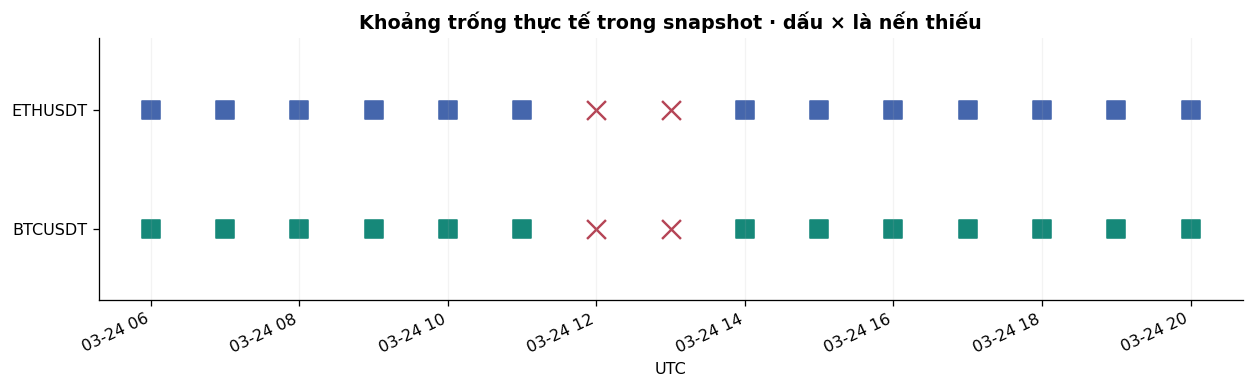

In [5]:
study.show(study.gap_chart(bars))

,ret_1,ret_4,ret_12,ret_24,vol_12,vol_48,rsi_14,macd,atr_14,volume_z,range_pct,body_pct,taker_ratio,ema_gap,hour_sin,hour_cos,dow_sin,dow_cos
count,67628.00000,67628.00000,67628.00000,67628.00000,67628.00000,67628.00000,67628.00000,67628.00000,67628.00000,67628.00000,67628.00000,67628.00000,67628.00000,67628.00000,67628.00000,67628.00000,67628.00000,67628.00000
mean,0.00003,0.00011,0.00034,0.00069,0.00482,0.00516,0.50569,0.00009,0.00757,-0.00617,0.00757,0.00004,0.49138,0.00023,0.00002,0.00005,0.00237,-0.00084
std,0.00574,0.01144,0.01995,0.02831,0.00313,0.00252,0.12133,0.00656,0.00409,1.08667,0.00651,0.00574,0.06928,0.01341,0.70713,0.70710,0.70689,0.70732
min,-0.12489,-0.16323,-0.22719,-0.27161,0.00038,0.00064,0.05392,-0.07076,0.00065,-3.28988,0.00018,-0.11741,0.11314,-0.13494,-1.00000,-1.00000,-0.97493,-0.90097
25%,-0.00216,-0.00430,-0.00829,-0.01256,0.00272,0.00346,0.42859,-0.00269,0.00487,-0.81369,0.00371,-0.00216,0.44867,-0.00575,-0.70711,-0.70711,-0.78183,-0.90097
50%,0.00004,0.00012,0.00036,0.00064,0.00409,0.00465,0.50459,0.00017,0.00682,-0.12755,0.00585,0.00004,0.49246,0.00031,0.00000,0.00000,0.00000,-0.22252
75%,0.00230,0.00466,0.00887,0.01345,0.00607,0.00629,0.58199,0.00305,0.00933,0.69321,0.00929,0.00231,0.53438,0.00668,0.70711,0.70711,0.78183,0.62349
max,0.09126,0.14827,0.17865,0.22072,0.04146,0.02512,0.96603,0.04364,0.05663,5.49599,0.23924,0.09555,0.86087,0.08637,1.00000,1.00000,0.97493,1.00000


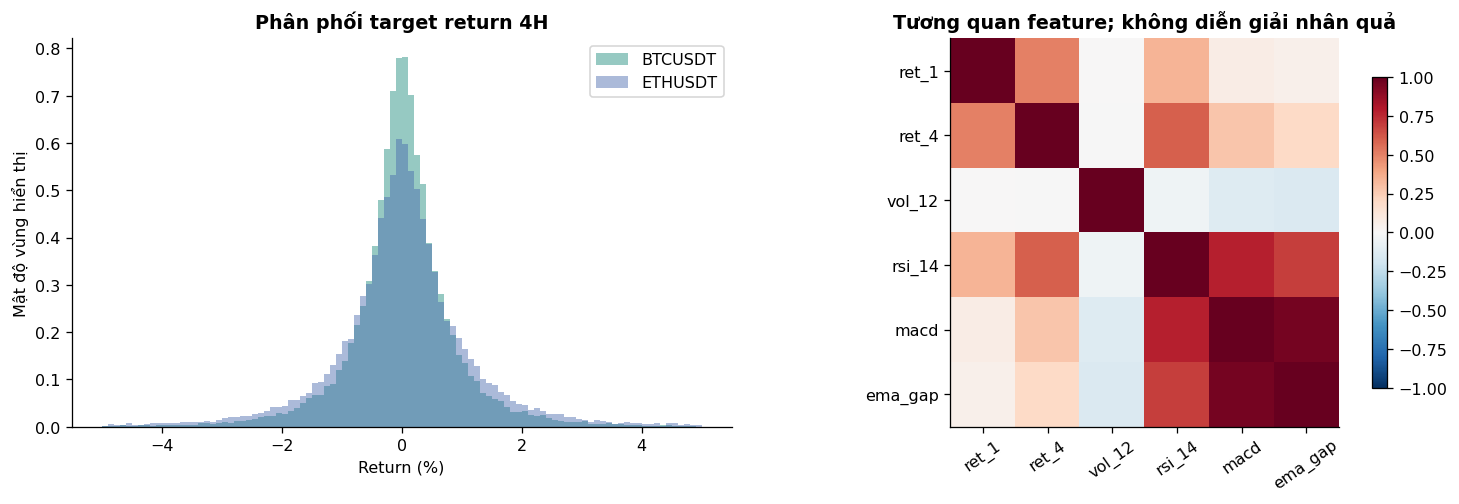

In [6]:
display(samples[study.FEATURES].describe().round(5))
study.show(study.features_chart(samples))

,fold,train_rows,validation_rows,last_train_label,validation_start,validation_end_exclusive
0,1,65700,622,2026-10-05 06:00:00+00:00,2026-10-05 07:00:00+00:00,2026-10-18 11:00:00+00:00
1,2,66332,622,2026-10-18 10:00:00+00:00,2026-10-18 11:00:00+00:00,2026-10-31 15:00:00+00:00
2,3,66964,634,2026-10-31 14:00:00+00:00,2026-10-31 15:00:00+00:00,2026-11-14 01:00:00+00:00


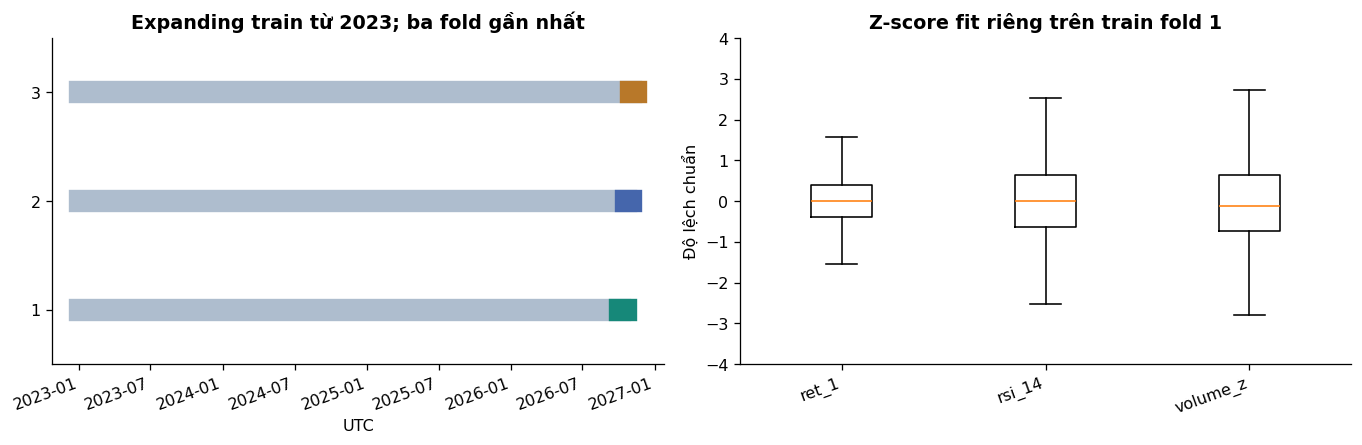

In [7]:
splits, fig = study.split_chart(bars, samples, cfg)
display(splits)
study.show(fig)

18 features; scaler fit train; nhãn vượt biên fold đã purge.


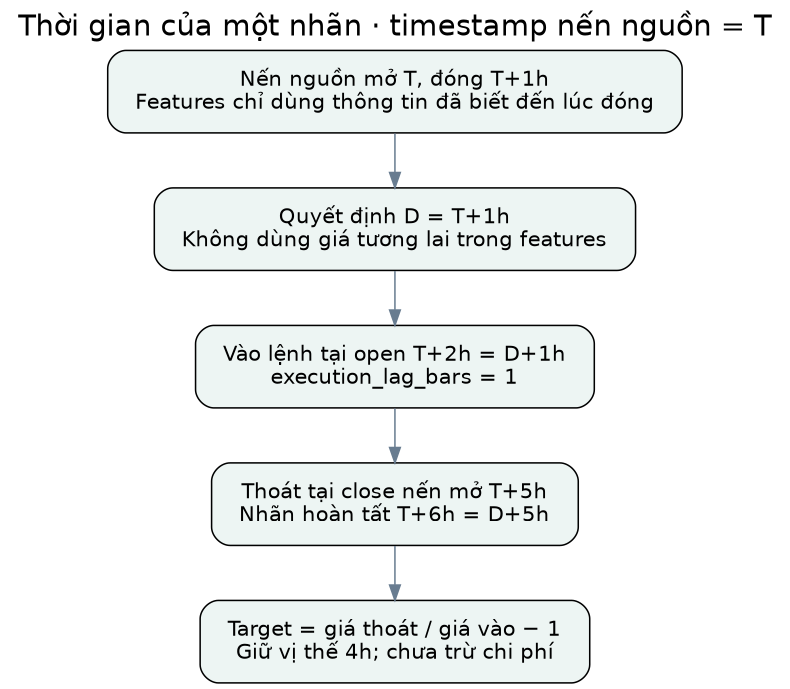

In [8]:
study.diagram('target')
assert samples.loc[samples.target_return.notna(), 'label_end_time'].sub(samples.loc[samples.target_return.notna(), 'decision_time']).eq(__import__('pandas').Timedelta(hours=5)).all()
print('18 features; scaler fit train; nhãn vượt biên fold đã purge.')